# 06 · Analyses

1. **Position bias.** Listwise Llama on the same test queries, with candidates in v1's positives-first order, shuffled, and reversed.
2. **Stage-1 diagnostic.** Recall of the true references in Qwen3's top k, for k = 5, 10, 20, 50. This tests v1's "stage-1 recall loss" explanation.
3. **Contamination check.** The LLM's gain over Qwen3 for queries published before vs after Llama 3.2's knowledge cutoff. Meta's model card says: "The pretraining data has a cutoff of December 2023."
4. **LLM reliability.** Listwise outputs that were partial or unparseable.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
BENCHES = ["concept", "random"]
SPLIT = "test"
CUTOFF = "2023-12-31"
BASELINE = "qwen"

In [3]:
import json
from src.pipeline_v2 import load_eval_sets, load_runs
from src.stats_v2 import contamination_split, per_query, position_bias, stage1_recall

C = json.loads((RESEARCH / "v2" / "config.json").read_text())
TAG = f"{C['fields']}_{C['max_chars']}_{C['query_max_chars']}"
runs = {b: load_runs(b, TAG, split=SPLIT) for b in BENCHES}

### 1 · Position bias

If the LLM uses content rather than position, MRR and R-precision should not depend on the input order.

In [4]:
pb = {}
for bench, df in runs.items():
    pb[bench] = position_bias(df[df["seed"].isin(df[df["order"] != "shuffled"]["seed"].unique())], "llama")
    print(bench); display(pb[bench])

concept


,order,queries,mrr,mrr_lo,mrr_hi,rprec,rprec_lo,rprec_hi,top1
0,original,118,0.9786,0.9523,1.0000,74.0661,69.5700,78.4370,0.9746
1,reversed,118,0.2745,0.2125,0.3388,19.8994,14.3096,25.8596,0.1695
2,shuffled,118,0.6085,0.5535,0.6636,43.1042,40.1870,46.1042,0.3559


random


,order,queries,mrr,mrr_lo,mrr_hi,rprec,rprec_lo,rprec_hi,top1
0,original,118,0.9466,0.9068,0.9843,72.2950,66.7758,77.4977,0.9407
1,reversed,118,0.3340,0.2659,0.4038,29.9876,23.1049,37.3729,0.2288
2,shuffled,118,0.6627,0.6060,0.7190,46.3262,42.6011,50.1356,0.4407


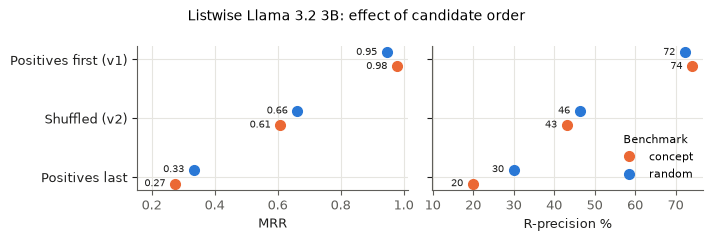

In [5]:
from src.figures import fig_position_bias
save(fig_position_bias(pb), "06_position_bias")

**Figure (06_position_bias).** Listwise Llama 3.2 3B on the same test queries and seed, with candidates in three input orders. "Positives first" reproduces v1's order. Differences between rows measure position bias.

### 2 · Stage-1 recall (Qwen3, BM25 and a hybrid)

The hybrid fuses the stored BM25 and Qwen3 rankings with Reciprocal Rank Fusion (k = 60), so it needs no extra model calls. Pools hold at most 42 candidates, so recall@50 is trivially 100%; full-corpus recall is a Phase 5 question.

In [6]:
from src.pipeline_v2 import RunConfig
from src.stats_v2 import rrf_runs

recalls = {}
for bench, df in runs.items():
    cfg = RunConfig(bench=bench, fields=C["fields"], max_chars=C["max_chars"], query_max_chars=C["query_max_chars"])
    hybrid = rrf_runs(bench, cfg, split=SPLIT)
    both = pd.concat([df, hybrid])
    recalls[bench] = {m: stage1_recall(both, m) for m in ("qwen", "bm25", "bm25+qwen (RRF)")}
    print(bench, "| hybrid R-precision:", round(hybrid["rprec"].mean(), 1))
    display(pd.concat({m: r["mean"] for m, r in recalls[bench].items()}, axis=1).round(3))

concept | hybrid R-precision: 72.8


,qwen,bm25,bm25+qwen (RRF)
recall@5,0.638,0.518,0.580
recall@10,0.890,0.762,0.842
recall@20,0.979,0.947,0.975
recall@50,1.000,1.000,1.000


random | hybrid R-precision: 78.7


,qwen,bm25,bm25+qwen (RRF)
recall@5,0.676,0.568,0.629
recall@10,0.925,0.808,0.890
recall@20,0.990,0.961,0.987
recall@50,1.000,1.000,1.000


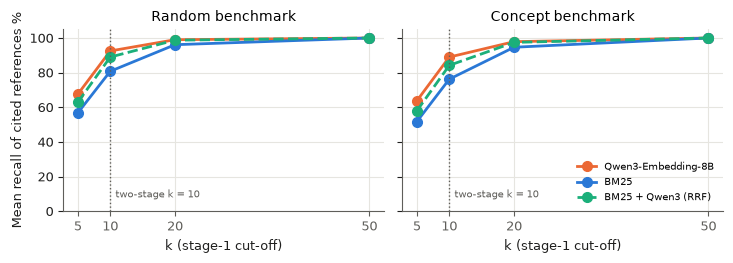

In [7]:
from src.figures import fig_stage1_recall
save(fig_stage1_recall(recalls, k_used=C["stage1_k"]), "06_stage1_recall")

**Figure (06_stage1_recall).** Mean share of each query's cited references that a first-stage method ranks in its top k: Qwen3, BM25, and their RRF hybrid. At the two-stage cut-off (k = 10), Qwen3 keeps about 90% of them, so a two-stage drop cannot be blamed on stage-1 recall.

### 3 · Contamination check

**Caveat:** almost all queries were published before the cutoff, so the "after" group is tiny. Read this as a limitation, not as evidence either way.

In [8]:
for bench, df in runs.items():
    ds = load_eval_sets(bench)
    dates = {s["pi_id"]: s["pi_date"] for s in ds["sets"]}
    print(bench); display(contamination_split(per_query(df), dates, CUTOFF, "llama", BASELINE))

concept


,period,queries,llm,baseline,gain
0,after cutoff,1,50.9091,100.0000,-49.0909
1,before cutoff,117,41.9536,79.9046,-37.9511


random


,period,queries,llm,baseline,gain
0,after cutoff,1,38.1818,100.0000,-61.8182
1,before cutoff,117,43.9737,86.8651,-42.8914


### 4 · LLM output reliability

In [9]:
for bench, df in runs.items():
    llm = df[df["method"].str.startswith(("llama", "qwen→llama")) & (df["method"] != "llama+minilm")]
    print(bench); display(llm.groupby(["method", "order"])["status"].value_counts().unstack(fill_value=0))

concept


status                             ok  parse_fail  partial
method                  order                             
llama                   original   61           1       56
                        reversed   77           1       40
                        shuffled  360           0      230
llama-pointwise         shuffled  118           0        0
llama-window            shuffled  581           0        9
qwen→llama_k10_shuffled shuffled  587           0        3

random


status                             ok  parse_fail  partial
method                  order                             
llama                   original   66           0       52
                        reversed   78           1       39
                        shuffled  365           3      222
llama-pointwise         shuffled  118           0        0
llama-window            shuffled  576           0       14
qwen→llama_k10_shuffled shuffled  586           0        4

### Findings

- **Position bias explains v1.** Listwise Llama was run on the same test queries and candidates in three orders (seed 0; 95% bootstrap CIs; `random` / `concept`).
  - **Positives first** (v1's order): MRR 0.95 [0.91, 0.98] / 0.98 [0.95, 1.00] and R-precision 72 [67, 77] / 74 [70, 78]. This reproduces and exceeds v1's headline MRR 0.84.
  - **Shuffled:** MRR 0.66 [0.61, 0.72] / 0.61 [0.55, 0.66].
  - **Positives last:** MRR 0.33 [0.27, 0.40] / 0.27 [0.21, 0.34], below chance (about 0.56) on both benchmarks. R-precision is 30 [23, 37] / 20 [14, 26], below chance (33.3) on `concept`; on `random` the CI includes chance.
  - **Top-1 accuracy** goes from 94–98% to 17–23%.
  - The conditions use v2's neutral prompt and shared candidate text. Only the order (audit F1) changes, not v1's `[3, 1, 7, ...]` example or title + concepts input. Order alone is therefore enough to reproduce v1's result: the model ranks largely by input position, not content.
- **Stage-1 recall is not the bottleneck.**
  - Qwen3's top 10 holds 93% (`random`) and 89% (`concept`) of the cited references on average. Its top 20 holds 99% and 98%.
  - BM25 keeps less (81% and 76% at k = 10). The BM25 + Qwen3 RRF hybrid (89% and 84%; R-precision 78.7 and 72.8) does not beat Qwen3 alone (87.0 and 80.1): BM25 pulls the fused ranking down.
  - The two-stage drop seen in `05_stats` (13.0 and 10.4 points below Qwen3 alone) therefore comes from the Llama reranking step, not from references lost at stage 1. This contradicts v1's explanation (audit F5).
- **Contamination cannot be tested with these queries.** Llama 3.2's pretraining data has a cutoff of December 2023 (Meta model card). Only two of the 168 queries are later, and only one is in the test split. The before/after comparison is therefore not interpretable. Testing contamination would need queries published after the cutoff, which is a candidate for the full-corpus experiment.
- **Listwise output is unreliable at full length.**
  - Full-list Llama returns a partial ranking in 38% of calls (452 of 1,180 across both benchmarks) and an unparseable one in 3.
  - With the sliding window (at most 10 candidates per call), 23 of 1,180 queries had any partial window.
  - Pointwise calls never failed.